
# HOSVD-Based Face Recognition

This implementation follows these steps:

1. Build the image tensor.
2. Compute HOSVD and plot singular values for the three modes separately.
3. Use **all `wink` images as the test set**, apply the HOSVD face-recognition algorithm, test `tol = {0.1, 0.01, 0.001}`, and visualize the predicted subjects.
4. Solve the same recognition problem with a **rank-k truncated HOSVD** for `k = {2, 5, 10}` and report the effect of `k`.


In [11]:

# ============================================================
# 0. Imports, dataset extraction, and reproducible ordering
# ============================================================

import os
import re
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# Locate the Yale Face archive.
candidate_archives = [
    '/content/drive/MyDrive/yaleface.zip',
    '/content/drive/MyDrive/yaleface',
]

archive_path = next((p for p in candidate_archives if os.path.isfile(p)), None)
if archive_path is None:
    raise FileNotFoundError(
        'Yale Face archive was not found. Update candidate_archives with the correct path.'
    )

extract_dir = '/content/yaleface_hosvd'
os.makedirs(extract_dir, exist_ok=True)

# Extract only when the dataset has not already been extracted.
marker = os.path.join(extract_dir, '.extracted')
if not os.path.exists(marker):
    with zipfile.ZipFile(archive_path, 'r') as zf:
        zf.extractall(extract_dir)
    open(marker, 'w').close()

# Read every GIF image from the extracted dataset.
image_paths = sorted(
    glob.glob(os.path.join(extract_dir, '**', '*.gif'), recursive=True)
)

pattern = re.compile(r'^(subject\d+)\.([^.]+)\.gif$', re.IGNORECASE)

records = []
for path in image_paths:
    filename = os.path.basename(path)
    match = pattern.match(filename)
    if match:
        subject = match.group(1)
        expression = match.group(2).lower()
        records.append((subject, expression, path))

if not records:
    raise RuntimeError('No Yale Face images matching subjectXX.expression.gif were found.')

subjects = sorted(
    {r[0] for r in records},
    key=lambda s: int(re.search(r'\d+', s).group())
)

all_expressions = sorted({r[1] for r in records})
print(f'Total images found: {len(records)}')
print(f'Subjects: {len(subjects)} -> {subjects}')
print(f'Expressions in archive: {len(all_expressions)} -> {all_expressions}')


Total images found: 180
Subjects: 15 -> ['subject01', 'subject02', 'subject03', 'subject04', 'subject05', 'subject06', 'subject07', 'subject08', 'subject09', 'subject10', 'subject11', 'subject12', 'subject13', 'subject14', 'subject15']
Expressions in archive: 11 -> ['centerlight', 'glasses', 'happy', 'leftlight', 'noglasses', 'normal', 'rightlight', 'sad', 'sleepy', 'surprised', 'wink']


In [2]:

# ============================================================
# 1. Build the training tensor A and the wink test set
# ============================================================

# wink is deliberately excluded from the training expressions.
test_expression = 'wink'
train_expressions = [e for e in all_expressions if e != test_expression]

print(f'Training expressions ({len(train_expressions)}): {train_expressions}')
print(f'Test expression: {test_expression}')

record_map = {(subject, expression): path for subject, expression, path in records}

missing = [
    (subject, expression)
    for subject in subjects
    for expression in train_expressions + [test_expression]
    if (subject, expression) not in record_map
]
if missing:
    raise RuntimeError(f'Missing expected images: {missing[:10]}')

# Read one image to determine the flattened image length and image shape.
sample_path = record_map[(subjects[0], train_expressions[0])]
sample_img = np.array(Image.open(sample_path).convert('L'))
image_shape = sample_img.shape
image_length = sample_img.size

print(f'Image shape: {image_shape}')
print(f'Flattened image length l: {image_length}')

# A has shape: (pixels, facial expressions, subjects)
# This directly matches A in R^(l x m x n).
A = np.zeros((image_length, len(train_expressions), len(subjects)), dtype=np.float64)

for e_idx, expression in enumerate(train_expressions):
    for s_idx, subject in enumerate(subjects):
        img = np.array(
            Image.open(record_map[(subject, expression)]).convert('L'),
            dtype=np.float64
        )
        if img.shape != image_shape:
            raise ValueError(
                f'Image size mismatch for {subject}.{expression}: {img.shape}'
            )
        A[:, e_idx, s_idx] = img.reshape(-1)

# All wink images are stored separately as the test matrix.
# Column i corresponds to subjects[i].
wink_test = np.zeros((image_length, len(subjects)), dtype=np.float64)

for s_idx, subject in enumerate(subjects):
    img = np.array(
        Image.open(record_map[(subject, test_expression)]).convert('L'),
        dtype=np.float64
    )
    wink_test[:, s_idx] = img.reshape(-1)

print(f'\nTraining tensor A shape: {A.shape}')
print(f'Wink test matrix shape: {wink_test.shape}')
print('Expected training shape: (77760, 10, 15) for the supplied Yale Face archive.')


Training expressions (10): ['centerlight', 'glasses', 'happy', 'leftlight', 'noglasses', 'normal', 'rightlight', 'sad', 'sleepy', 'surprised']
Test expression: wink
Image shape: (243, 320)
Flattened image length l: 77760

Training tensor A shape: (77760, 10, 15)
Wink test matrix shape: (77760, 15)
Expected training shape: (77760, 10, 15) for the supplied Yale Face archive.



### Tensor organization

The tensor is organized where mode 1 is the image/pixel-vector mode, mode 2 is the facial-expression mode, and mode 3 is the subject mode.

Because `wink` is held out completely, the training tensor has 10 facial-expression states and 15 subjects.


In [3]:

# ============================================================
# 2. Tensor utilities and HOSVD
# ============================================================

def unfold(X, mode):
    """Mode-n unfolding with zero-based mode indexing."""
    return np.reshape(
        np.moveaxis(X, mode, 0),
        (X.shape[mode], -1)
    )


def mode_product(X, U, mode):
    """Multiply tensor X by matrix U along the selected mode.

    U must have shape (new_mode_size, old_mode_size).
    """
    result = np.tensordot(U, X, axes=(1, mode))
    return np.moveaxis(result, 0, mode)


def hosvd(X):
    """Compute the full HOSVD of a 3-way tensor."""
    factors = []
    for mode in range(3):
        U, _, _ = np.linalg.svd(
            unfold(X, mode),
            full_matrices=False
        )
        factors.append(U)

    core = X.copy()
    for mode, U in enumerate(factors):
        core = mode_product(core, U.T, mode)

    return core, factors


# HOSVD of the training tensor.
core, (U1, U2, U3) = hosvd(A)

print('HOSVD factor shapes:')
print(f'U1 (image mode):       {U1.shape}')
print(f'U2 (expression mode):  {U2.shape}')
print(f'U3 (subject mode):     {U3.shape}')
print(f'Core tensor:            {core.shape}')


HOSVD factor shapes:
U1 (image mode):       (77760, 150)
U2 (expression mode):  (10, 10)
U3 (subject mode):     (15, 15)
Core tensor:            (150, 10, 15)


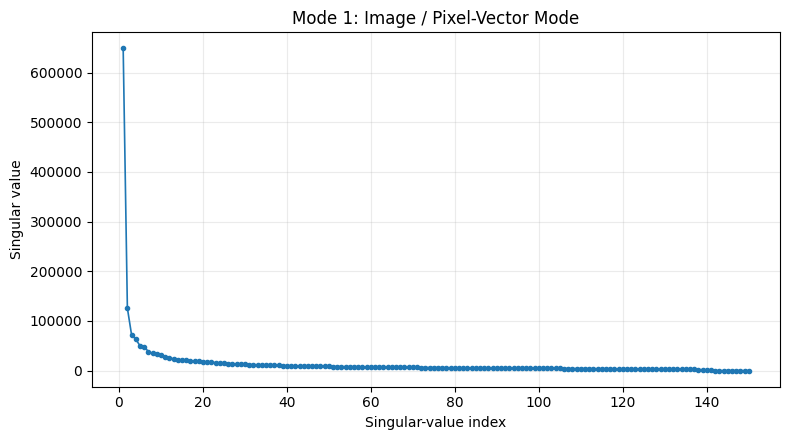

Mode 1: Image / Pixel-Vector Mode
  k=2: cumulative energy = 93.5135%
  k=5: cumulative energy = 96.0158%
  k=10: cumulative energy = 97.5486%



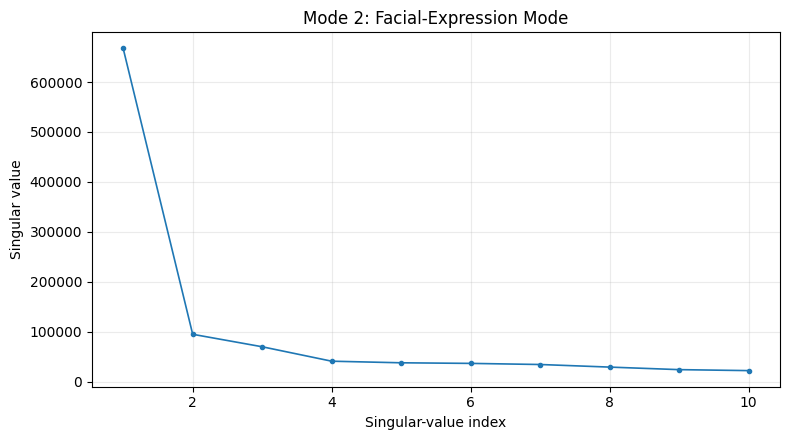

Mode 2: Facial-Expression Mode
  k=2: cumulative energy = 97.2970%
  k=5: cumulative energy = 99.0286%
  k=10: cumulative energy = 100.0000%



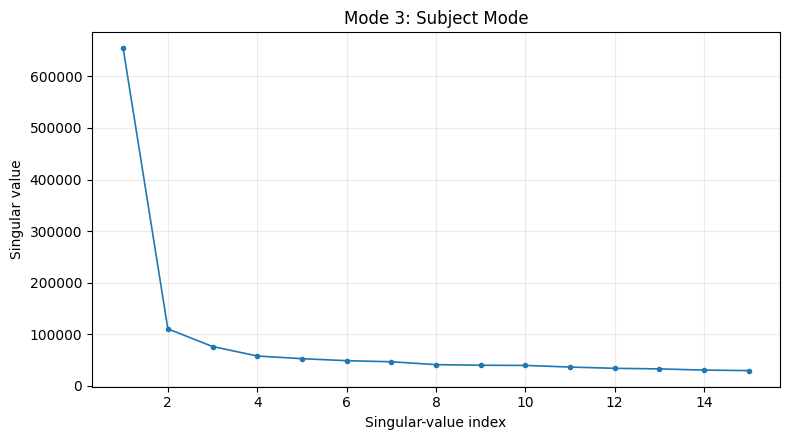

Mode 3: Subject Mode
  k=2: cumulative energy = 94.2691%
  k=5: cumulative energy = 96.8287%
  k=10: cumulative energy = 98.8479%



In [4]:

# ============================================================
# 3. Singular values for the three modes
# ============================================================

singular_values = [
    np.linalg.svd(unfold(A, mode), compute_uv=False)
    for mode in range(3)
]

mode_names = [
    'Mode 1: Image / Pixel-Vector Mode',
    'Mode 2: Facial-Expression Mode',
    'Mode 3: Subject Mode'
]

# three separate plots.
for mode, (sv, title) in enumerate(zip(singular_values, mode_names), start=1):
    plt.figure(figsize=(8, 4.5))
    plt.plot(
        np.arange(1, len(sv) + 1),
        sv,
        marker='o',
        markersize=3,
        linewidth=1.2
    )
    plt.xlabel('Singular-value index')
    plt.ylabel('Singular value')
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    # Energy information is useful when discussing truncation.
    energy = (sv ** 2) / np.sum(sv ** 2)
    cumulative_energy = np.cumsum(energy)

    print(f'{title}')
    for k in [2, 5, 10]:
        if k <= len(sv):
            print(
                f'  k={k}: cumulative energy = '
                f'{cumulative_energy[k-1] * 100:.4f}%'
            )
    print()



### Recognition Output

In [5]:

# ============================================================
# 4. HOSVD face-recognition classifier
# ============================================================

# C is equivalent to S x1 U1 x2 U2 from the HOSVD.
# It can be obtained more directly as A x3 U3^T.
C = mode_product(A, U3.T, mode=2)

# Pre-compute the pseudo-inverse of each expression slice.
# C_e has shape (pixels, subjects), so pinv(C_e) has shape (subjects, pixels).
C_pinv = np.stack(
    [np.linalg.pinv(C[:, e, :]) for e in range(C.shape[1])],
    axis=0
)

def classify_hosvd(image, C_tensor, factor_subject, tol=None):
    """Recognize a face using the HOSVD face-recognition rule.

    For every training expression e:
        alpha_e = pinv(C_e) @ image

    alpha_e is compared with every subject row of U3.
    The globally closest (expression, subject) pair is selected.
    """
    best_distance = np.inf
    best_expression_idx = None
    best_subject_idx = None

    for e in range(C_tensor.shape[1]):
        C_e = C_tensor[:, e, :]

        # Estimate the subject-mode coefficient vector.
        alpha = np.linalg.pinv(C_e) @ image

        # Compare alpha with the ROWS of U3.
        # Each row represents one subject in the subject-mode basis.
        distances = np.linalg.norm(
            factor_subject - alpha[None, :],
            axis=1
        )

        subject_idx = int(np.argmin(distances))
        distance = float(distances[subject_idx])

        if distance < best_distance:
            best_distance = distance
            best_expression_idx = e
            best_subject_idx = subject_idx

    accepted = True if tol is None else best_distance <= tol

    return {
        'expression_idx': best_expression_idx,
        'subject_idx': best_subject_idx,
        'distance': best_distance,
        'accepted': accepted
    }


def evaluate_hosvd(tol):
    """Evaluate all 15 wink test images at a given tolerance."""
    rows = []

    for test_idx, true_subject in enumerate(subjects):
        result = classify_hosvd(
            wink_test[:, test_idx],
            C,
            U3,
            tol=tol
        )

        pred_subject = (
            subjects[result['subject_idx']]
            if result['accepted']
            else None
        )

        predicted_expression = (
            train_expressions[result['expression_idx']]
            if result['accepted']
            else None
        )

        rows.append({
            'test_subject': true_subject,
            'predicted_subject': pred_subject,
            'predicted_expression': predicted_expression,
            'distance': result['distance'],
            'accepted': result['accepted'],
            'correct': (
                pred_subject == true_subject
                if pred_subject is not None
                else False
            )
        })

    return pd.DataFrame(rows)



===== HOSVD results: tol = 0.1 =====
Accepted predictions: 2/15
Coverage:             13.33%
Accuracy among accepted predictions: 100.00%
Correct predictions / all test images: 2/15 (13.33%)


,test_subject,predicted_subject,predicted_expression,distance,accepted,correct
0,subject01,None,None,0.257265,False,False
1,subject02,None,None,0.334595,False,False
2,subject03,None,None,0.126506,False,False
3,subject04,None,None,0.146791,False,False
4,subject05,subject05,normal,0.059812,True,True
5,subject06,subject06,sad,0.066443,True,True
6,subject07,None,None,0.348468,False,False
7,subject08,None,None,0.600439,False,False
8,subject09,None,None,0.322291,False,False
9,subject10,None,None,0.135859,False,False


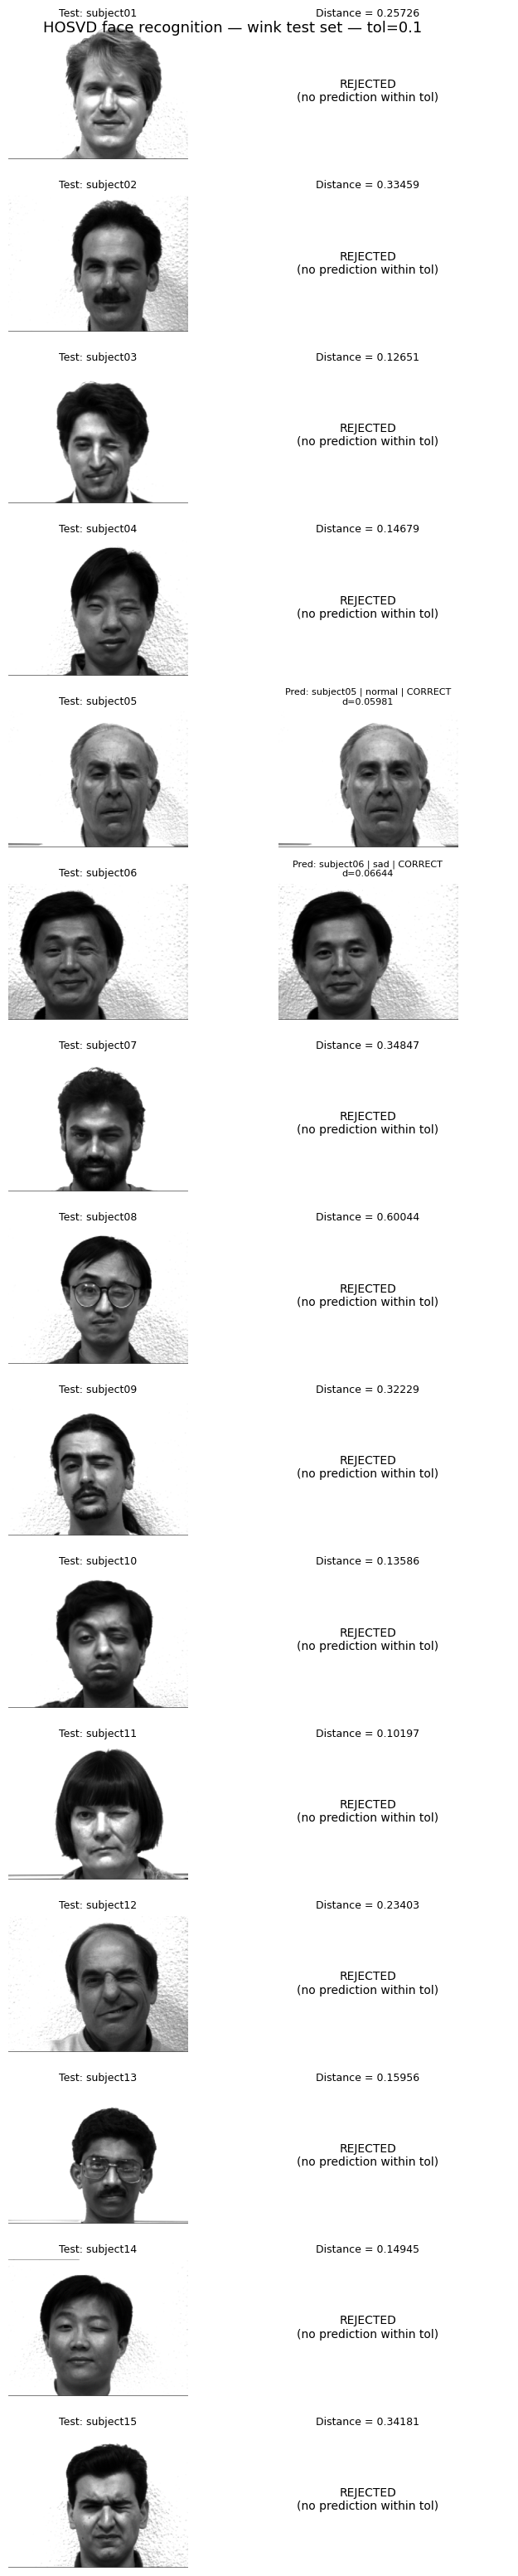


===== HOSVD results: tol = 0.01 =====
Accepted predictions: 0/15
Coverage:             0.00%
Accuracy among accepted predictions: 0.00%
Correct predictions / all test images: 0/15 (0.00%)


,test_subject,predicted_subject,predicted_expression,distance,accepted,correct
0,subject01,None,None,0.257265,False,False
1,subject02,None,None,0.334595,False,False
2,subject03,None,None,0.126506,False,False
3,subject04,None,None,0.146791,False,False
4,subject05,None,None,0.059812,False,False
5,subject06,None,None,0.066443,False,False
6,subject07,None,None,0.348468,False,False
7,subject08,None,None,0.600439,False,False
8,subject09,None,None,0.322291,False,False
9,subject10,None,None,0.135859,False,False


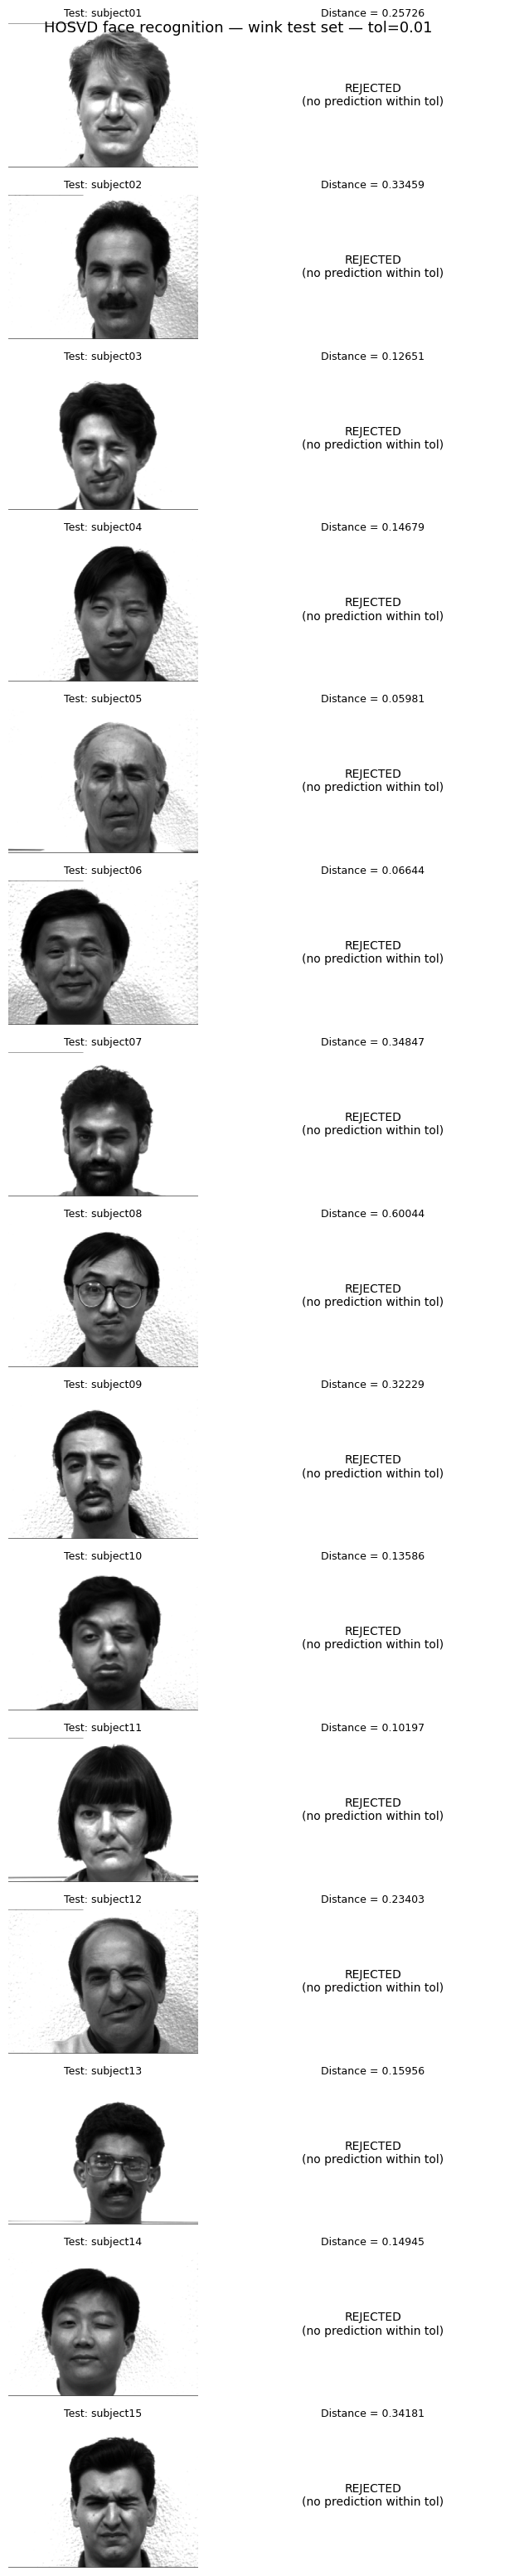


===== HOSVD results: tol = 0.001 =====
Accepted predictions: 0/15
Coverage:             0.00%
Accuracy among accepted predictions: 0.00%
Correct predictions / all test images: 0/15 (0.00%)


,test_subject,predicted_subject,predicted_expression,distance,accepted,correct
0,subject01,None,None,0.257265,False,False
1,subject02,None,None,0.334595,False,False
2,subject03,None,None,0.126506,False,False
3,subject04,None,None,0.146791,False,False
4,subject05,None,None,0.059812,False,False
5,subject06,None,None,0.066443,False,False
6,subject07,None,None,0.348468,False,False
7,subject08,None,None,0.600439,False,False
8,subject09,None,None,0.322291,False,False
9,subject10,None,None,0.135859,False,False


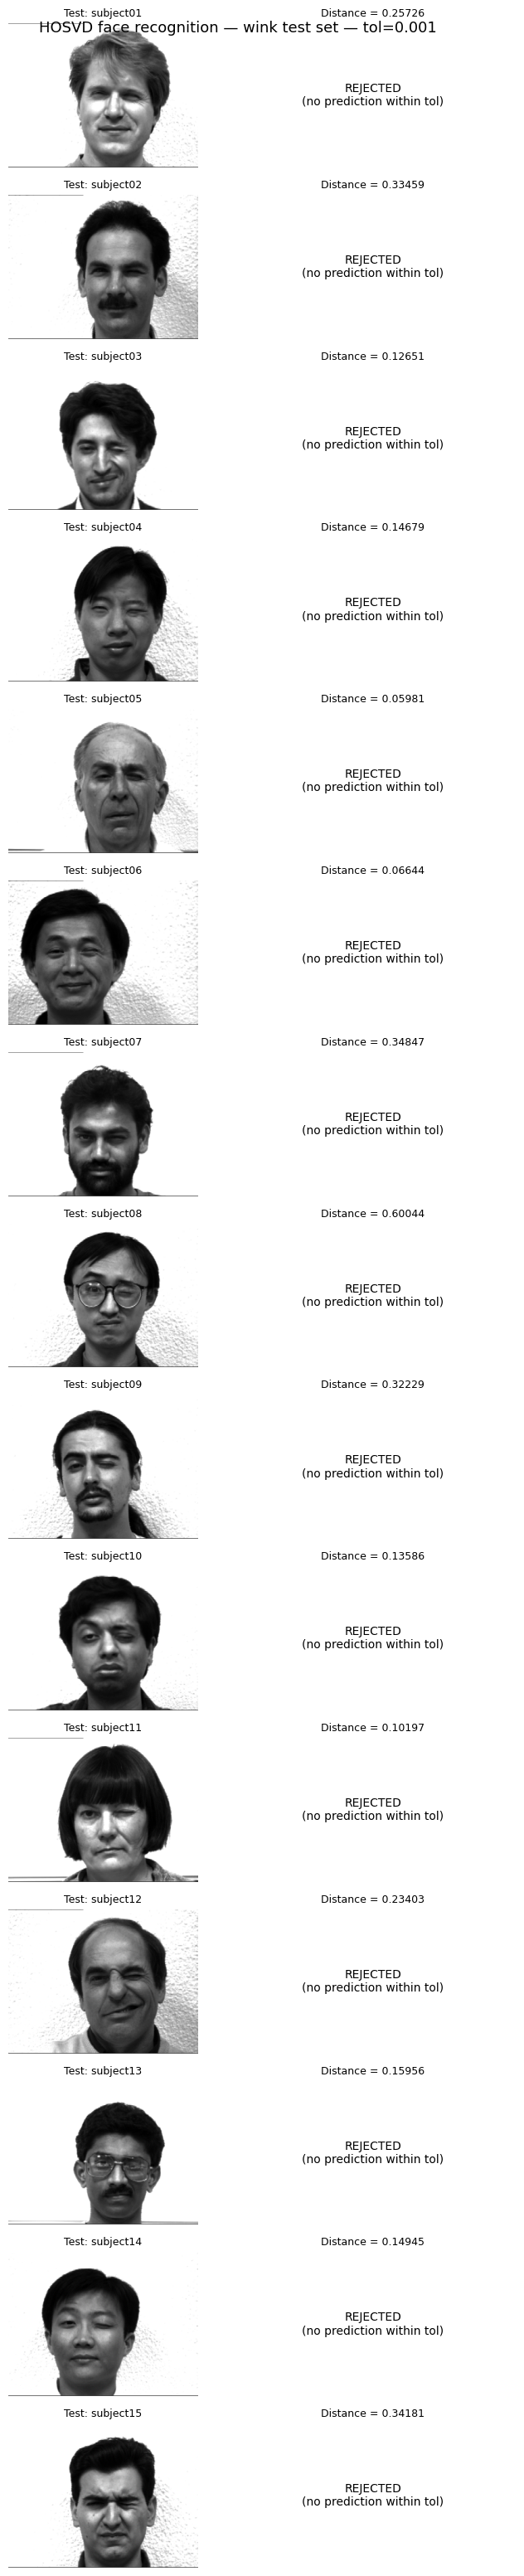

In [6]:

# ============================================================
# 5. Test tol = {0.1, 0.01, 0.001} and visualize predictions
# ============================================================

tolerances = [0.1, 0.01, 0.001]
hosvd_results = {}

for tol in tolerances:
    df = evaluate_hosvd(tol)
    hosvd_results[tol] = df

    accepted = int(df['accepted'].sum())
    correct_accepted = int(df.loc[df['accepted'], 'correct'].sum())

    coverage = accepted / len(df)
    accuracy_accepted = (
        correct_accepted / accepted if accepted > 0 else 0.0
    )
    strict_accuracy = correct_accepted / len(df)

    print(f'\n===== HOSVD results: tol = {tol} =====')
    print(f'Accepted predictions: {accepted}/{len(df)}')
    print(f'Coverage:             {coverage * 100:.2f}%')
    print(
        f'Accuracy among accepted predictions: '
        f'{accuracy_accepted * 100:.2f}%'
    )
    print(
        f'Correct predictions / all test images: '
        f'{correct_accepted}/{len(df)} '
        f'({strict_accuracy * 100:.2f}%)'
    )

    display(df)

    # Visualize every wink test image and its matched training face.
    # A rejected image is explicitly marked instead of silently omitted.
    fig, axes = plt.subplots(
        nrows=len(subjects),
        ncols=2,
        figsize=(7, len(subjects) * 2.1)
    )

    for i, row in df.iterrows():
        # Original test image.
        axes[i, 0].imshow(
            wink_test[:, i].reshape(image_shape),
            cmap='gray'
        )
        axes[i, 0].set_title(
            f"Test: {row['test_subject']}",
            fontsize=9
        )
        axes[i, 0].axis('off')

        # Predicted training image.
        if row['accepted']:
            s_idx = subjects.index(row['predicted_subject'])
            e_idx = train_expressions.index(row['predicted_expression'])

            axes[i, 1].imshow(
                A[:, e_idx, s_idx].reshape(image_shape),
                cmap='gray'
            )

            status = 'CORRECT' if row['correct'] else 'WRONG'
            axes[i, 1].set_title(
                f"Pred: {row['predicted_subject']} | "
                f"{row['predicted_expression']} | {status}\n"
                f"d={row['distance']:.5f}",
                fontsize=8
            )
        else:
            axes[i, 1].text(
                0.5, 0.5,
                'REJECTED\n(no prediction within tol)',
                ha='center',
                va='center',
                fontsize=10
            )
            axes[i, 1].set_title(
                f"Distance = {row['distance']:.5f}",
                fontsize=9
            )

        axes[i, 1].axis('off')

    fig.suptitle(
        f'HOSVD face recognition — wink test set — tol={tol}',
        fontsize=13
    )
    plt.tight_layout()
    plt.show()



## 6. Truncated HOSVD

For the recognition rule above, the subject-mode factor is directly used to identify the person, while the expression index is used to select an expression slice.

Therefore, a recognition-compatible truncated HOSVD keeps:
- the first `k` components of the image mode,
- the full expression mode (10 training expressions), so the expression slices remain identifiable,
- the first `k` components of the subject mode.

Thus the reduced representation has rank

\[
(k,\,10,\,k)
\]

for `k = 2, 5, 10`.

This avoids an important ambiguity: if the expression mode were also reduced to `k`, the reduced mode-2 indices would no longer correspond one-to-one to the original facial-expression labels used by the recognition algorithm.


In [7]:

# ============================================================
# 7. Truncated HOSVD classifier
# ============================================================

def build_truncated_hosvd(A, k):
    """Build a recognition-compatible rank-k HOSVD representation.

    Mode 1 (image mode): retain k components.
    Mode 2 (expression mode): retain all training expressions.
    Mode 3 (subject mode): retain k components.

    The resulting C_k has shape (k, expressions, k).
    """
    if k > U1.shape[1] or k > U3.shape[1]:
        raise ValueError(f'k={k} is too large for the available ranks.')

    U1_k = U1[:, :k]
    U3_k = U3[:, :k]

    # Compress image and subject modes.
    C_k = mode_product(A, U1_k.T, mode=0)
    C_k = mode_product(C_k, U3_k.T, mode=2)

    return U1_k, U3_k, C_k


def classify_truncated(image, U1_k, U3_k, C_k, tol=None):
    """Classify one test image in the truncated HOSVD space."""
    # Project the test image into the same reduced image space.
    image_k = U1_k.T @ image

    best_distance = np.inf
    best_expression_idx = None
    best_subject_idx = None

    for e in range(C_k.shape[1]):
        C_e = C_k[:, e, :]

        # Estimate the reduced subject-mode coefficient vector.
        alpha = np.linalg.pinv(C_e) @ image_k

        # Compare with rows of the reduced subject factor.
        distances = np.linalg.norm(
            U3_k - alpha[None, :],
            axis=1
        )

        subject_idx = int(np.argmin(distances))
        distance = float(distances[subject_idx])

        if distance < best_distance:
            best_distance = distance
            best_expression_idx = e
            best_subject_idx = subject_idx

    accepted = True if tol is None else best_distance <= tol

    return {
        'expression_idx': best_expression_idx,
        'subject_idx': best_subject_idx,
        'distance': best_distance,
        'accepted': accepted
    }


def evaluate_truncated(k, tol):
    """Evaluate all wink test images for a selected truncation rank k."""
    U1_k, U3_k, C_k = build_truncated_hosvd(A, k)

    rows = []
    for test_idx, true_subject in enumerate(subjects):
        result = classify_truncated(
            wink_test[:, test_idx],
            U1_k,
            U3_k,
            C_k,
            tol=tol
        )

        pred_subject = (
            subjects[result['subject_idx']]
            if result['accepted']
            else None
        )

        predicted_expression = (
            train_expressions[result['expression_idx']]
            if result['accepted']
            else None
        )

        rows.append({
            'k': k,
            'tol': tol,
            'test_subject': true_subject,
            'predicted_subject': pred_subject,
            'predicted_expression': predicted_expression,
            'distance': result['distance'],
            'accepted': result['accepted'],
            'correct': (
                pred_subject == true_subject
                if pred_subject is not None
                else False
            )
        })

    return pd.DataFrame(rows)


In [8]:

# ============================================================
# 8. Solve the problem for k = {2, 5, 10}
# ============================================================

k_values = [2, 5, 10]
truncated_results = []

for k in k_values:
    for tol in tolerances:
        df_k = evaluate_truncated(k, tol)

        accepted = int(df_k['accepted'].sum())
        correct_accepted = int(
            df_k.loc[df_k['accepted'], 'correct'].sum()
        )

        coverage = accepted / len(df_k)
        accuracy_accepted = (
            correct_accepted / accepted if accepted > 0 else 0.0
        )

        truncated_results.append({
            'k': k,
            'tol': tol,
            'accepted': accepted,
            'coverage_%': 100 * coverage,
            'correct_accepted': correct_accepted,
            'accuracy_accepted_%': 100 * accuracy_accepted,
            'mean_distance': df_k['distance'].mean()
        })

truncated_summary = pd.DataFrame(truncated_results)

print('===== Truncated HOSVD summary =====')
display(truncated_summary.sort_values(['k', 'tol']))


===== Truncated HOSVD summary =====


,k,tol,accepted,coverage_%,correct_accepted,accuracy_accepted_%,mean_distance
2,2,0.001,0,0.000000,0,0.000000,0.015693
1,2,0.010,9,60.000000,4,44.444444,0.015693
0,2,0.100,15,100.000000,6,40.000000,0.015693
5,5,0.001,0,0.000000,0,0.000000,0.375051
4,5,0.010,0,0.000000,0,0.000000,0.375051
3,5,0.100,1,6.666667,1,100.000000,0.375051
8,10,0.001,0,0.000000,0,0.000000,0.675376
7,10,0.010,0,0.000000,0,0.000000,0.675376
6,10,0.100,2,13.333333,2,100.000000,0.675376


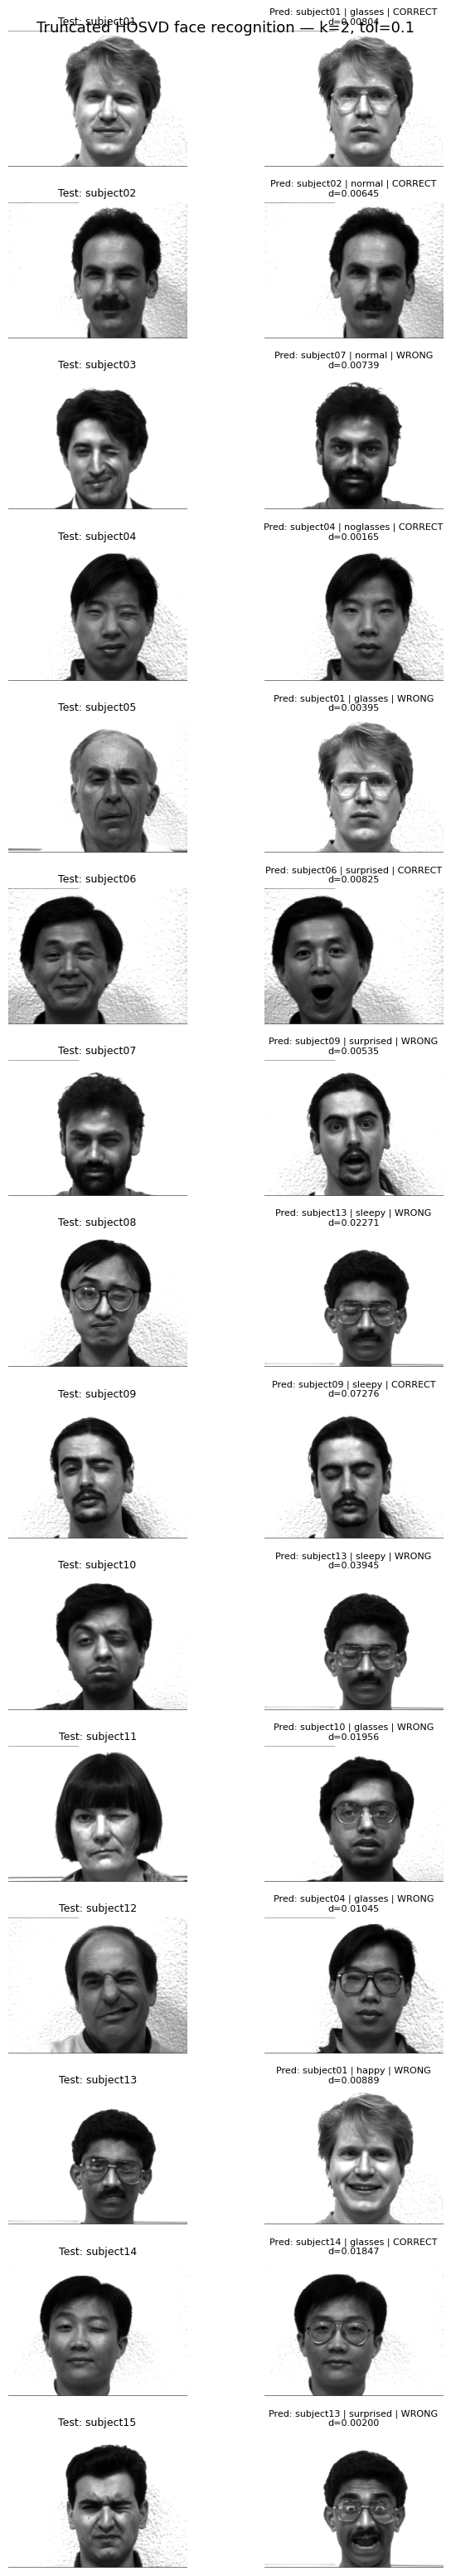

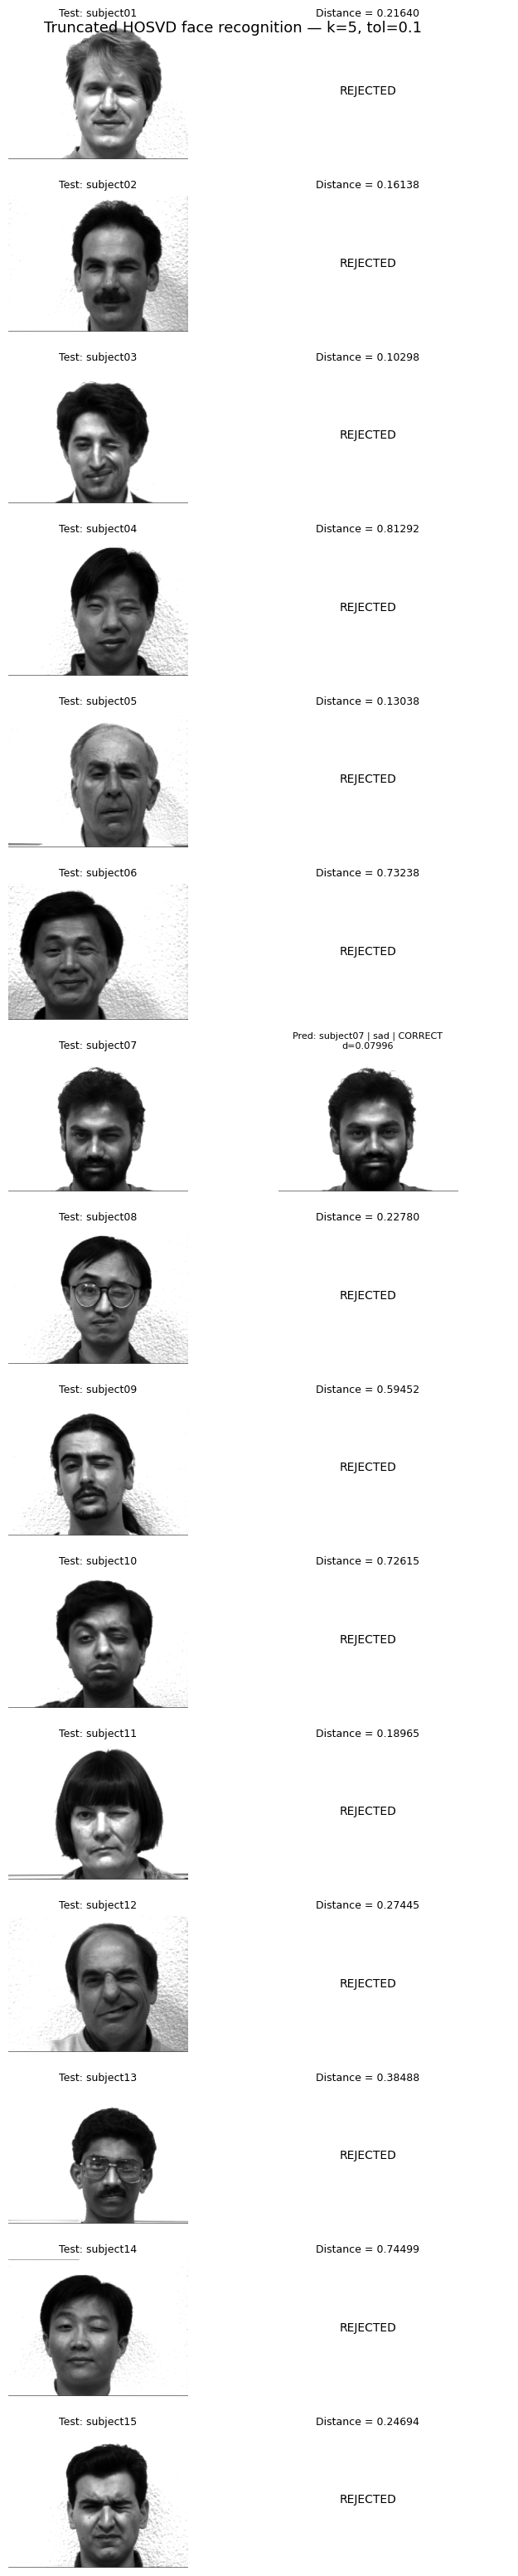

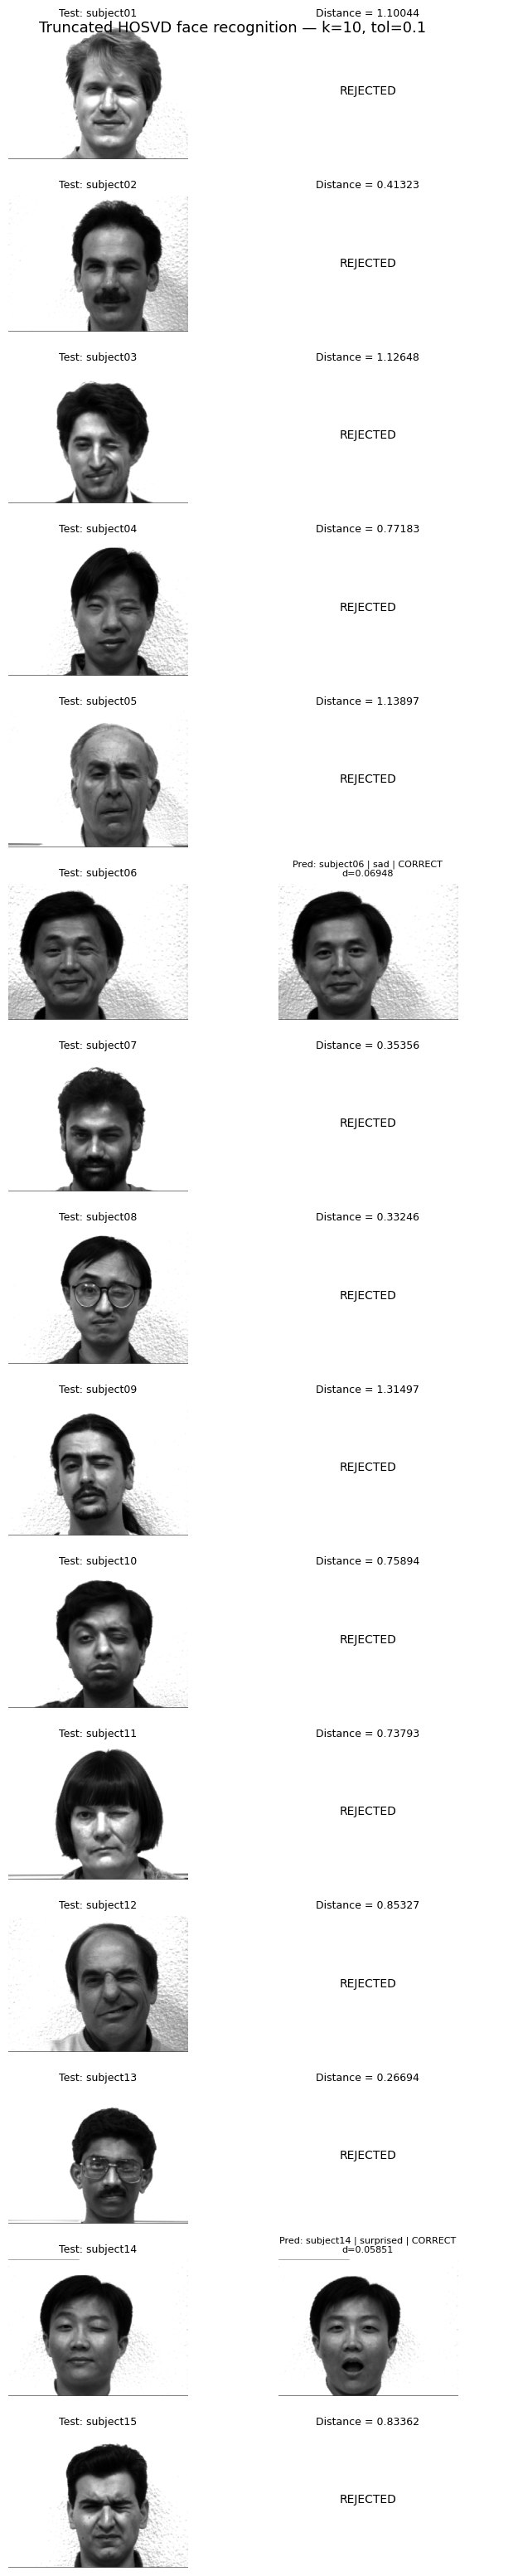

In [9]:

# ============================================================
# 9. Visualize predictions for each k at tol = 0.1
# ============================================================
# tol=0.1 is shown here as a compact visual comparison across k.
# The complete numerical comparison for all three tolerances is
# contained in truncated_summary above.

visual_tol = 0.1

for k in k_values:
    df_k = evaluate_truncated(k, visual_tol)

    fig, axes = plt.subplots(
        nrows=len(subjects),
        ncols=2,
        figsize=(7, len(subjects) * 2.1)
    )

    for i, row in df_k.iterrows():
        axes[i, 0].imshow(
            wink_test[:, i].reshape(image_shape),
            cmap='gray'
        )
        axes[i, 0].set_title(
            f"Test: {row['test_subject']}",
            fontsize=9
        )
        axes[i, 0].axis('off')

        if row['accepted']:
            s_idx = subjects.index(row['predicted_subject'])
            e_idx = train_expressions.index(row['predicted_expression'])

            axes[i, 1].imshow(
                A[:, e_idx, s_idx].reshape(image_shape),
                cmap='gray'
            )

            status = 'CORRECT' if row['correct'] else 'WRONG'
            axes[i, 1].set_title(
                f"Pred: {row['predicted_subject']} | "
                f"{row['predicted_expression']} | {status}\n"
                f"d={row['distance']:.5f}",
                fontsize=8
            )
        else:
            axes[i, 1].text(
                0.5, 0.5,
                'REJECTED',
                ha='center',
                va='center'
            )
            axes[i, 1].set_title(
                f"Distance = {row['distance']:.5f}",
                fontsize=9
            )

        axes[i, 1].axis('off')

    fig.suptitle(
        f'Truncated HOSVD face recognition — k={k}, tol={visual_tol}',
        fontsize=13
    )
    plt.tight_layout()
    plt.show()


In [10]:

# ============================================================
# 10. Compact final comparison table
# ============================================================

# Full HOSVD results for all tolerances.
full_summary_rows = []
for tol, df in hosvd_results.items():
    accepted = int(df['accepted'].sum())
    correct_accepted = int(df.loc[df['accepted'], 'correct'].sum())

    full_summary_rows.append({
        'method': 'Full HOSVD',
        'k': 'full',
        'tol': tol,
        'accepted': accepted,
        'coverage_%': 100 * accepted / len(df),
        'accuracy_accepted_%': (
            100 * correct_accepted / accepted
            if accepted else 0.0
        ),
        'mean_distance': df['distance'].mean()
    })

full_summary = pd.DataFrame(full_summary_rows)

final_comparison = pd.concat(
    [
        full_summary,
        truncated_summary.rename(columns={
            'accuracy_accepted_%': 'accuracy_accepted_%'
        })[
            [
                'k', 'tol', 'accepted', 'coverage_%',
                'accuracy_accepted_%', 'mean_distance'
            ]
        ].assign(method='Truncated HOSVD')[
            [
                'method', 'k', 'tol', 'accepted',
                'coverage_%', 'accuracy_accepted_%', 'mean_distance'
            ]
        ]
    ],
    ignore_index=True
)

display(final_comparison)


,method,k,tol,accepted,coverage_%,accuracy_accepted_%,mean_distance
0,Full HOSVD,full,0.100,2,13.333333,100.000000,0.225686
1,Full HOSVD,full,0.010,0,0.000000,0.000000,0.225686
2,Full HOSVD,full,0.001,0,0.000000,0.000000,0.225686
3,Truncated HOSVD,2,0.100,15,100.000000,40.000000,0.015693
4,Truncated HOSVD,2,0.010,9,60.000000,44.444444,0.015693
5,Truncated HOSVD,2,0.001,0,0.000000,0.000000,0.015693
6,Truncated HOSVD,5,0.100,1,6.666667,100.000000,0.375051
7,Truncated HOSVD,5,0.010,0,0.000000,0.000000,0.375051
8,Truncated HOSVD,5,0.001,0,0.000000,0.000000,0.375051
9,Truncated HOSVD,10,0.100,2,13.333333,100.000000,0.675376


## 11. Analysis of Results

### 1) Data and training tensor
- 180 images were read (15 subjects × 11 expressions). The `wink` expression was held out entirely and used as the test set (15 images).
- The training tensor has shape $77760 \times 10 \times 15$ (pixels × expressions × subjects). HOSVD gives $U_1 \in \mathbb{R}^{77760\times150}$, $U_2 \in \mathbb{R}^{10\times10}$, $U_3 \in \mathbb{R}^{15\times15}$.
- Because `wink` is absent from training, the task is to identify a person under an **unseen expression**, which is inherently harder than recognizing faces under training expressions.

### 2) Singular values of the three modes
| Mode | Cum. energy k=2 | k=5 | k=10 |
|---|---|---|---|
| 1 (image) | 93.51% | 96.02% | 97.55% |
| 2 (expression) | 97.30% | 99.03% | 100% |
| 3 (subject) | 94.27% | 96.83% | 98.85% |

- In all three plots the **first singular value dominates** (about $6.5\times10^5$ versus roughly $1\text{–}1.3\times10^5$ for the second), followed by a sharp drop and a nearly flat tail. Since the images were not mean-centered, the first component mostly captures the "average face / overall brightness". The >93% energy at k=2 therefore does not mean high identity information.
- Mode 2 reaches a flat region right after the first component, and it trivially reaches 100% at k=10 because it only has 10 dimensions. Modes 1 and 3 have longer tails, meaning the details that separate subjects are spread over later, low-energy components.

### 3) Full HOSVD on the `wink` test set
| tol | Accepted | Coverage | Accuracy among accepted | Correct out of 15 |
|---|---|---|---|---|
| 0.1 | 2 / 15 | 13.3% | 100% | 2 (13.3%) |
| 0.01 | 0 | 0% | – | 0 |
| 0.001 | 0 | 0% | – | 0 |

- At tol=0.1 only `subject05` (matched to `normal`, distance ≈ 0.0598) and `subject06` (matched to `sad`, distance ≈ 0.0664) were accepted, and both were correct.
- **Distances do not depend on tol** (mean ≈ 0.226 in all three runs); tol is only a rejection threshold. The smallest observed distance is ≈ 0.06, so tol=0.01 and 0.001 are far too strict and accept nothing.
- The remaining distances range from about 0.10 (`subject11`, ≈ 0.102, barely above the threshold) up to 0.60 (`subject08`). This indicates the `wink` face is poorly reconstructed by any of the 10 training expression slices.
- Net effect: **very high precision but very low recall**. When the method commits to a decision it is usually right, but it almost never commits. The 100% accuracy rests on only 2 samples and is not statistically meaningful.

### 4) Truncated HOSVD with rank $(k, 10, k)$
| k | tol | Accepted | Correct | Mean distance |
|---|---|---|---|---|
| 2 | 0.1 | 15 | 6 (40%) | 0.0157 |
| 2 | 0.01 | 9 | 4 (44.4%) | 0.0157 |
| 2 | 0.001 | 0 | 0 | 0.0157 |
| 5 | 0.1 | 1 | 1 (100%) | 0.375 |
| 5 | ≤0.01 | 0 | 0 | 0.375 |
| 10 | 0.1 | 2 | 2 (100%) | 0.675 |
| 10 | ≤0.01 | 0 | 0 | 0.675 |

- **Effect of k on coverage:** at k=2 distances are tiny (mean ≈ 0.016), so almost everything falls under the threshold (100% coverage at tol=0.1). As k grows, distances grow (0.375 at k=5, 0.675 at k=10) and coverage drops to 6.7% and 13.3%.
- **Distances are not comparable across different k.** The rows of $U_3$ are truncated singular vectors, and their squared norms sum to k, so at small k all subjects sit close to the origin and close to each other. A fixed tol is then too loose at k=2 and comparatively tight at k=10. The high coverage at k=2 is not a sign of quality; it reflects weak separation between subjects in a 2-D space.
- **Actual accuracy at k=2 is also weak:** when all 15 images were accepted, only 6 were correct (40%). From the prediction figure, errors concentrate on a few subjects (e.g. `subject13` was wrongly chosen three times, `subject01` twice), and several wrong matches use the `sleepy` expression, which looks similar to `wink` (closed eye). This suggests that at k=2 global appearance cues (lighting, glasses, eye state) dominate rather than identity.
- The 100% accuracy at k=5 and k=10 is based on 1 and 2 samples and is not reliable. By "correct out of 15", the ordering is k=2 (6) > k=10 and full HOSVD (2 each) > k=5 (1), but because of the scale issue this ranking should not be read as model quality.
- The non-monotonic behavior (mean distance at k=10 is 0.675, larger than 0.226 for full HOSVD) shows that truncating the image and subject modes does more than compress: it changes the geometry of the comparison. The exact cause cannot be established from these outputs alone.

### 5) Conclusions
1. **Cumulative energy is a poor guide for choosing k in face recognition.** The (uncentered) first component saturates the energy while carrying little identity information.
2. **tol must be matched to the scale of the distances.** Values 0.01 and 0.001 produced no predictions for full HOSVD and for k=5/10, while tol=0.1 accepts almost everything at k=2.
3. **The best precision/coverage balance in this experiment is full HOSVD at tol=0.1** (perfect precision but only 13% coverage). No configuration performs acceptably on all 15 `wink` images.
4. Limitations: only 15 test images (each is ≈ 6.7% accuracy) and `wink` is unseen in training, so small differences between configurations are not meaningful.